In [1]:
import pandas as pd
import polars as pl
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
outputs_dir = "../3_outputs/sqY2H"

df = pl.read_csv(f'{outputs_dir}/edges_df.csv', null_values=".", infer_schema_length=10000)

# dedup
df = df.with_columns(
    pl.when(pl.col("aa_change").is_null())
    .then(pl.lit("wt"))
    .otherwise(pl.col("aa_change"))
    .alias("aa_change")
)
df = df.with_columns(
    (pl.col("symbol") + "_" + 
     pl.col("ad_symbol") + "_" + 
     pl.col("aa_change")).alias("ppi_group_clean")
)

df = df.sort("db_mut_id", descending=True).unique(subset=["ppi_group_clean"], keep="first")

df
# drop WT

df = df.filter(pl.col("db_mut_id") != 0)

df = df.to_pandas()

df

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,...,seq_ad,seq_db,db_seq_final_right,manual_correction_applied,consensus_score,aa_score,consensus_manual_score_growth,wt_consensus_score,log2fc,ppi_group_clean
0,VUSAPWT2B1r05_010,G11,VUSAPWT2B1r05_007_008_009_010_011_012,VUSAPWT2B1,r17,LWH25,2,False,1235,None,...,1,1,Y,False,124.486898,5.238443,2.0,469.198393,-1.905733,LITAF_HPCAL4_Ala111Gly
1,VUSAPWT6B1r04_004,K07,VUSAPWT6B1r04_001_002_003_004_005_006,VUSAPWT6B1,r16,LWH10,6,False,6985,None,...,1,1,Y,False,389.075419,0.297184,3.0,386.166166,0.010800,NAA10_CCDC174_Arg116Trp
2,VUSAPWT1B1r05_009,K11,VUSAPWT1B1r05_007_008_009_010_011_012,VUSAPWT1B1,r11,LWH25,1,False,13662,None,...,1,1,Y,True,487.999199,6.324980,3.0,358.208705,0.445010,AGXT_CYSRT1_Ser221Pro
3,VUSAPWT1B1r05_016,M15,VUSAPWT1B1r05_013_014_015_016_017_018,VUSAPWT1B1,r11,LWH25,1,False,71001,None,...,1,1,Y,False,340.669046,13.076756,3.0,440.222558,-0.368907,LITAF_UBQLN2_Thr49Met
4,VUSAPWT1B1r04_014,G09,VUSAPWT1B1r04_013_014_015_016_017_018,VUSAPWT1B1,r10,LWH10,1,False,14441,None,...,1,1,Y,False,402.545739,NaN,NaN,400.835487,0.006127,LITAF_GGA3_Val144Met
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1834,VUSAPWT1B1r04_040,M01,VUSAPWT1B1r04_037_038_039_040_041_042,VUSAPWT1B1,r10,LWH10,1,False,9342,None,...,1,1,Y,False,69.927855,15.704455,2.0,245.992394,-1.800042,EMD_BEND7_Ser54Phe
1835,VUSAPWT6B1r05_021,G17,VUSAPWT6B1r05_019_020_021_022_023_024,VUSAPWT6B1,r17,LWH25,6,False,6446,None,...,1,1,Y,False,8.721428,45.390304,0.0,449.049553,-5.532772,PLP1_ERGIC3_Thr147Pro
1836,VUSAPWT1B1r04_039,E17,VUSAPWT1B1r04_037_038_039_040_041_042,VUSAPWT1B1,r10,LWH10,1,False,53964,None,...,1,1,Y,False,0.039234,3.269856,0.0,467.962267,-8.817808,MLH1_NFIX_Ala586Asp
1837,VUSAPWT1B1r05_010,K07,VUSAPWT1B1r05_007_008_009_010_011_012,VUSAPWT1B1,r11,LWH25,1,False,13662,None,...,1,1,Y,False,320.460046,2.949137,3.0,358.208705,-0.160183,AGXT_CYSRT1_Arg289His


## NO WT SIGMA, ONLY ERROR

Optimizing parameters...

=== OPTIMIZED PARAMETERS ===
Mutant Mean (Fixed):          -5.0000
Mutant Intrinsic Sig: 1.8666
Measurement Error:    0.6503
Bound (Fixed):        -2.0000


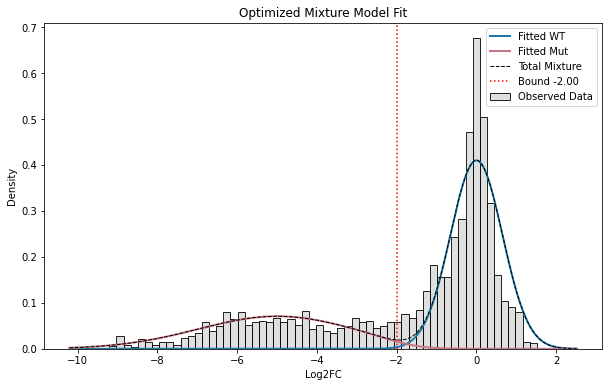


=== CUTOFFS ===
Log2FC at LLR > 3 (WT):      -1.1169
Log2FC at LLR < -3 (Mutant): -2.1325


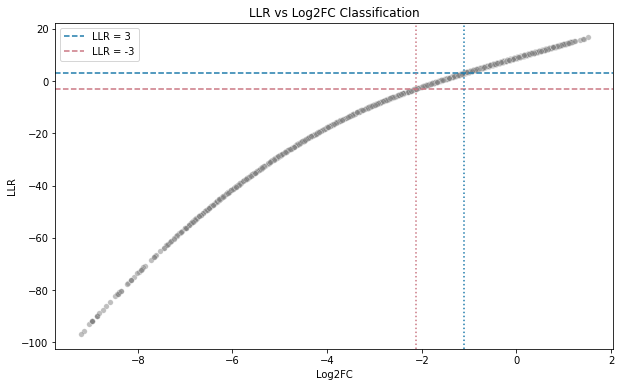

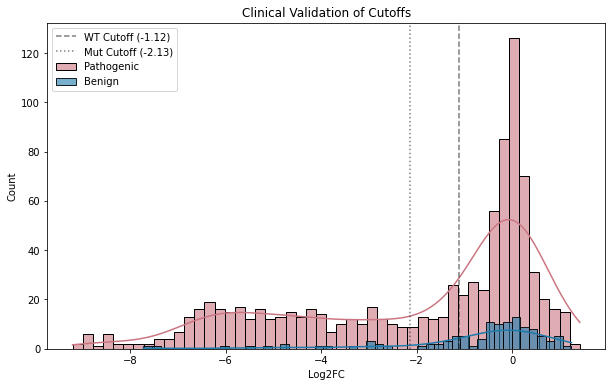

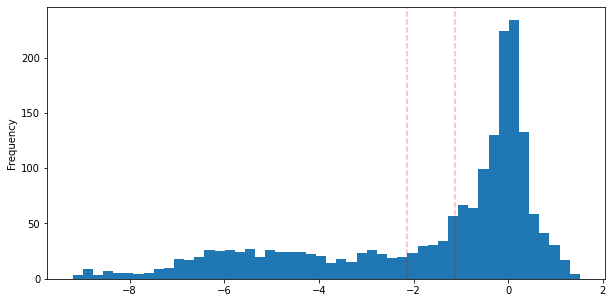

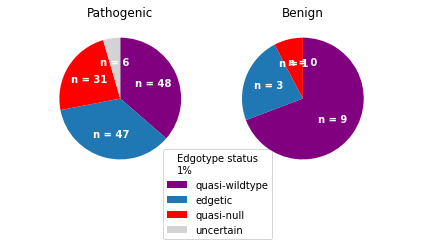

In [3]:
import pandas as pd
import numpy as np
import scipy.stats as stats
from scipy.optimize import minimize
import matplotlib.pyplot as plt
import seaborn as sns
import polars as pl

# ==========================================
# 1. SETUP & DATA LOADING
# ==========================================
log2fc_values = df['log2fc'].dropna().to_numpy()
FIXED_BOUND = -2 # Hard biological limit
FIXED_MU_PERTURBED = -5 # Fixed mean for mutant distribution

# ==========================================
# 2. HELPER FUNCTIONS
# ==========================================
def get_convolved_pdf(x_data, mu, sigma_bio, bound, sigma_error):
    """
    Computes the PDF of a Truncated Normal (intrinsic) convolved with Normal (noise).
    """
    var_prior = sigma_bio**2
    var_measurement = sigma_error**2
    sigma_combined = np.sqrt(var_prior + var_measurement)
    
    # A. Un-truncated distribution (Prior + Noise)
    log_py = stats.norm.logpdf(x_data, loc=mu, scale=sigma_combined)
    
    # B. Posterior Parameters for the Truncation Term
    var_post = 1.0 / (1.0 / var_prior + 1.0 / var_measurement)
    sigma_post = np.sqrt(var_post)
    mu_post = var_post * (mu / var_prior + x_data / var_measurement)
    
    # C. Truncation Adjustment Terms
    t = (bound - mu_post) / sigma_post
    log_post_cdf = stats.norm.logcdf(t)
    
    alpha = (bound - mu) / sigma_bio
    log_Z = stats.norm.logcdf(alpha)
    
    # Final Log PDF
    log_result = log_py + log_post_cdf - log_Z
    return np.exp(log_result)

def negative_log_likelihood(params):
    """
    Objective function for optimization.
    Params: [sigma_wt, mu_mut, sigma_mut, w_mut, sigma_error]
    """
    sigma_mut, w_mut, sigma_error = params
    
    
    # --- WT COMPONENT (Standard Normal Convolution) ---
    pdf_wt = stats.norm.pdf(log2fc_values, loc=0, scale=sigma_error)
    
    # --- MUTANT COMPONENT (Truncated Convolution) ---
    pdf_mut = get_convolved_pdf(log2fc_values, FIXED_MU_PERTURBED, sigma_mut, FIXED_BOUND, sigma_error)
    
    # --- MIXTURE ---
    pdf_mix = (1 - w_mut) * pdf_wt + w_mut * pdf_mut
    pdf_mix = np.maximum(pdf_mix, 1e-100) # Safety floor
    
    return -np.sum(np.log(pdf_mix))

# ==========================================
# 3. OPTIMIZATION
# ==========================================
# Guesses: sigma_wt, w_mut, sigma_error
initial_guess = [2.0, 0.2, 0.5]

bounds = [
    (0.5, 10.0),    # sigma_mut
    (0.01, 0.99),   # w_mut
    (0.01, 0.99)    # sigma_error
]

print("Optimizing parameters...")
res = minimize(negative_log_likelihood, initial_guess, bounds=bounds, method='L-BFGS-B')

# Unpack optimized parameters
opt_sigma_mut, opt_w_mut, opt_sigma_error = res.x

print("\n=== OPTIMIZED PARAMETERS ===")
print(f"Mutant Mean (Fixed):          {FIXED_MU_PERTURBED:.4f}")
print(f"Mutant Intrinsic Sig: {opt_sigma_mut:.4f}")
print(f"Measurement Error:    {opt_sigma_error:.4f}")
print(f"Bound (Fixed):        {FIXED_BOUND:.4f}")

# ==========================================
# 4. VISUALIZATION (FIT CHECK)
# ==========================================
plt.figure(figsize=(10, 6))
sns.histplot(log2fc_values, stat='density', bins=60, color='silver', alpha=0.5, label='Observed Data')

x_plot = np.linspace(min(log2fc_values)-1, max(log2fc_values)+1, 1000)

# WT Curve
y_wt = (1 - opt_w_mut) * stats.norm.pdf(x_plot, loc=0, scale=opt_sigma_error)

# Mut Curve
y_mut_raw = get_convolved_pdf(x_plot, FIXED_MU_PERTURBED, opt_sigma_mut, FIXED_BOUND, opt_sigma_error)
y_mut = opt_w_mut * y_mut_raw

# Total
y_total = y_wt + y_mut

plt.plot(x_plot, y_wt, color='#1D7AAB', lw=2, label='Fitted WT')
plt.plot(x_plot, y_mut, color='#CA7682', lw=2, label='Fitted Mut')
plt.plot(x_plot, y_total, color='black', linestyle='--', lw=1, label='Total Mixture')
plt.axvline(FIXED_BOUND, color='red', linestyle=':', label=f'Bound {FIXED_BOUND:.2f}')

plt.title("Optimized Mixture Model Fit")
plt.xlabel("Log2FC")
plt.ylabel("Density")
plt.legend()
plt.show()

# ==========================================
# 5. LLR CALCULATION
# ==========================================
def compute_perturbation_llr(df_in, mu_mut, sigma_mut, bound, sigma_error):
    """
    Calculates LLR using the consistent optimized parameters.
    """
    # Work on a copy (Pandas)
    df_out = df_in.copy()
    if isinstance(df_out, pl.DataFrame):
        df_out = df_out.to_pandas()
        
    log2fc = df_out["log2fc"].to_numpy()
    
    # Handle row-specific error if available, otherwise use optimized global error
    if "error_log2fc" in df_out.columns:
        row_error = df_out["error_log2fc"].fillna(sigma_error).to_numpy()
    else:
        row_error = np.full_like(log2fc, sigma_error)
        
    row_error = np.maximum(row_error, 1e-3) # Safety floor

    # --- Null Hypothesis (WT) ---
    # Model: Normal(0, scale = sqrt(Error^2 + Intrinsic_WT^2))
    # scale_wt = np.sqrt(row_error**2 + sigma_wt**2)
    loglik_wt = stats.norm.logpdf(log2fc, loc=0, scale=row_error)
    
    # --- Alt Hypothesis (Mutant) ---
    # Model: Convolved Truncated Normal
    pdt_mut = get_convolved_pdf(log2fc, mu_mut, sigma_mut, bound, row_error)
    loglik_mut = np.log(np.maximum(pdt_mut, 1e-100))  # Safety floor
    
    # --- Final Score ---
    # LLR = Log(P(WT)) - Log(P(Mut))
    # Positive = WT, Negative = Mutant
    df_out["perturbation_LLR"] = loglik_wt - loglik_mut
    
    return pl.from_pandas(df_out)

# Run Calculation
df_result_pl = compute_perturbation_llr(
    df, 
    mu_mut=FIXED_MU_PERTURBED, 
    sigma_mut=opt_sigma_mut,
    bound=FIXED_BOUND, 
    sigma_error=opt_sigma_error
)
df_result = df_result_pl.to_pandas()

# ==========================================
# 6. THRESHOLDS & VALIDATION PLOTS
# ==========================================
df_sorted = df_result.sort_values('perturbation_LLR')
x_vals = df_sorted['log2fc'].values
y_vals = df_sorted['perturbation_LLR'].values

# Interpolate Cutoffs
cutoff_wt = np.interp(3, y_vals, x_vals)
cutoff_mut = np.interp(-3, y_vals, x_vals)

print(f"\n=== CUTOFFS ===")
print(f"Log2FC at LLR > 3 (WT):      {cutoff_wt:.4f}")
print(f"Log2FC at LLR < -3 (Mutant): {cutoff_mut:.4f}")

# Plot 1: LLR Curve
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_result, x='log2fc', y='perturbation_LLR', alpha=0.5, color='grey', s=30)
plt.axhline(3, color='#1D7AAB', ls='--', label='LLR = 3')
plt.axhline(-3, color='#CA7682', ls='--', label='LLR = -3')
plt.axvline(cutoff_wt, color='#1D7AAB', ls=':')
plt.axvline(cutoff_mut, color='#CA7682', ls=':')
plt.title("LLR vs Log2FC Classification")
plt.xlabel("Log2FC")
plt.ylabel("LLR")
plt.legend()
plt.show()

# Plot 2: Pathogenic vs Benign Validation
pathogenic_df = df_result_pl.filter(
    pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Likely pathogenic"])
).to_pandas()

benign_df = df_result_pl.filter(
    pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Benign", "Likely benign"])
).to_pandas()

plt.figure(figsize=(10, 6))
sns.histplot(pathogenic_df["log2fc"], bins=50, kde=True, color="#CA7682", label="Pathogenic", alpha=0.6)
sns.histplot(benign_df["log2fc"], bins=50, kde=True, color="#1D7AAB", label="Benign", alpha=0.6)

plt.axvline(x=cutoff_wt, color='black', linestyle='--', alpha=0.5, label=f'WT Cutoff ({cutoff_wt:.2f})')
plt.axvline(x=cutoff_mut, color='black', linestyle=':', alpha=0.5, label=f'Mut Cutoff ({cutoff_mut:.2f})')

plt.title("Clinical Validation of Cutoffs")
plt.xlabel("Log2FC")
plt.legend()
plt.show()

# Plot combined histogram
df.log2fc.plot.hist(bins=50, figsize=(10,5))
plt.axvline(x=cutoff_wt, color='red', linestyle='--', alpha=0.3)
plt.axvline(x=cutoff_mut, color='red', linestyle='--', alpha=0.3)
plt.show()


## 

df = df_result_pl.with_columns(
    pl.when(pl.col('perturbation_LLR').is_null())
    .then(pl.lit(None))
    .when(pl.col('perturbation_LLR') <= -3)
    .then(pl.lit('perturbed'))
    .when(pl.col('perturbation_LLR') >= 3)
    .then(pl.lit('unperturbed'))
    .otherwise(pl.lit('uncertain'))
    .alias('perturbation_status')
)

df = df.to_pandas()

def edgotype_status(status_list):
    status_list = status_list.to_list()
    if len(status_list) == 1:
        return np.nan
    if pd.isnull(status_list).all():
        return np.nan
    if 'perturbed' in status_list and 'unperturbed' in status_list:
        return 'edgetic'
    elif status_list.count('perturbed') >= 2:
        return 'quasi-null'
    elif status_list.count('unperturbed') >= 2:
        return 'quasi-wildtype'
    else:
        return 'uncertain'

# N PPIs, N successful, N_perturbed, N_unperturbed, N-uncertain
edgotype = (df.loc[df['db_orf_id'] != 0, :]
            .groupby(["gene_variant"])
    ["perturbation_status"]
    .apply(edgotype_status)
)

edgotype = (df.loc[df['db_orf_id'] != 0, :]
            .groupby(["gene_variant"])
    ["perturbation_status"]
    .apply(edgotype_status)
)
edgotype = edgotype.to_frame().rename(columns={"perturbation_status": "edgotype_status"})
edgotype['n_ppi'] = (df.loc[df['db_orf_id'] != 0, :]
            .groupby(["gene_variant"])
    ["ad_symbol"]
    .nunique())
edgotype['n_measured_ppi'] = (df.loc[df['db_orf_id'] != 0, :]
            .groupby(["gene_variant"])
    ["log2fc"]
    .apply(lambda x: x.notnull().sum()))

for status in ['perturbed', 'unperturbed', 'uncertain']:
    edgotype[f'n_{status}'] = (df.loc[df['db_orf_id'] != 0, :]
            .groupby(["gene_variant"])
    ["perturbation_status"]
    .apply(lambda x: (x == status).sum()))
# TODO
edgotype = edgotype.reset_index()

n_b4 = edgotype.shape[0]
edgotype = pd.merge(edgotype, 
         df.loc[:, ['symbol', 
                    'gene_variant',
                    'clinvar_clnsig_clean',
                    ]].drop_duplicates(),
            on=["gene_variant"],
            how='left')


order = ['quasi-wildtype', 'edgetic', 'quasi-null', 'uncertain']

fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(6,12))
for cat, ax in zip(['Pathogenic', 'Benign'], axs):
    vc = (edgotype.loc[(edgotype['clinvar_clnsig_clean'] == cat)
                 & (edgotype['n_measured_ppi'] >= 2), 
                 'edgotype_status']
                 .value_counts(dropna=True)
                 .reindex(order))
    vc.plot.pie(ax=ax,
                autopct=lambda x: f"n = {x / 100 * vc.sum():.0f}",
                startangle=90,
                counterclock=False,
                colors=['purple', 'C0', 'red', 'lightgrey'],
                ylabel='',
                textprops={'color': 'white', 'weight': 'bold'},
                legend=True if cat == 'Pathogenic' else False,
                )
    ax.set_title(cat)
leg = axs[0].get_legend()
leg.set_title("Edgotype status\n1%")
leg.set_loc("upper left")
leg.set_bbox_to_anchor((0.75, 0.2))